# **TCN for Classification of Knee Osteoarthritis Severity**

A Final Project by Aghnia Tias Salsabila

# I. Preparing the Environment

In [1]:
!pip install focal-loss

In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

from focal_loss import SparseCategoricalFocalLoss 

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
print(f'TensorFlow version : {tf.__version__}')
print(f'GPU available      : {len(tf.config.list_physical_devices("GPU")) > 0}')

2026-07-08 13:28:40.582249: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783517320.816894     117 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783517320.889897     117 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1783517321.426104     117 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783517321.426145     117 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783517321.426148     117 computation_placer.cc:177] computation placer alr

TensorFlow version : 2.19.0
GPU available      : True


# II. Configuration

* Class & Path
  -------

In [3]:
DATA_DIR   = '/kaggle/input/datasets/salsaaghnia/datasetnobutter/NON ANOMALIES FOLDERS DATASET'  # main folder that consists subfolder of each classes
CLASSES    = ["KOA_EL", "KOA_MD", "KOA_SV"]
ANGLE_COLS = ["knee_angle_clean", "hip_angle_clean"]  # the value from csv files that will be used
CLIP_RANGES = {
    "knee_angle_clean": (80.0, 185.0),
    "hip_angle_clean":  (-60.0, 60.0),
}
ADD_VELOCITY = True
VELOCITY_FOR = ["knee_angle_clean"] 
ADD_ACCELERATION = True   # knee angular acceleration (2nd derivative of knee angle)
# ADD_JOINT_DIFF   = True   # joint diff = knee_angle - hip_angle (coupling signal)

* Sliding Window Configuration
  -------

In [4]:
WINDOW_SIZE = 50  # the n values frame per window
STRIDE      = 25   # 50% overlap step size for sliding window

* TCN Hyperparameters
  -------

In [5]:
N_FILTERS      = 32        # the n filter values for each Conv1D
KERNEL_SIZE    = 6         # temporal window size for convolution
DILATION_RATES = [1, 2, 4, 8]   # dilation : receptive field expands exponentially
N_TCN_BLOCKS   = 5         # number of residual blocks in the stack
DROPOUT_RATE   = 0.2       # percentage of neurons to turn off during training (0.2-0.5)
L2_REG         = 0.001     # penalty for complex weights to keep the model general

* Training
  -------

In [6]:
EPOCHS        = 100       # maximum training cycles 
BATCH_SIZE    = 32       # the number of samples processed by the model
LEARNING_RATE = 0.0001    # initial step size for the optimizer
# PATIENCE      = 30        # early stopping threshold

* Data Splitting
  -------

  The data splitted from sliding window data results

In [7]:
TEST_SIZE = 0.15         # 15% data splitted for testing
VAL_SIZE  = 0.15         # 15% data splitted for validation
SEED      = 1           # to ensure data shuffling/splitting is consistent

* Output
  -------

In [8]:
RESULTS_DIR  = "results/"
MODEL_PATH   = "tcn_koa_model.h5"

os.makedirs(RESULTS_DIR, exist_ok=True)
print('[OK] Configuration done. RESULTS_DIR created.')

[OK] Configuration done. RESULTS_DIR created.


# III. SUBJECT-LEVEL DATA SPLITTING 

This cell is to split the data at the patient level.

This approach:

* Splits at the patient level (not video) → eliminates data leakage.

* Stratifies by class + gender simultaneously.

* Generates CSV evidence for documentation.


In [9]:
import shutil

# cleanup residual file from previous folder
# shutil.rmtree(BASE_SPLIT, ignore_errors=True)

# Path 
# Folder that contains all 159 csv files
SUMBER_CSV = '/kaggle/input/datasets/salsaaghnia/datasetnobutter/NON ANOMALIES DATASET'

# Destination Folder after splitting 
BASE_SPLIT  = './dataset_split'

# Metadata files
# Columns: subject_id, class, gender, age, heights
META_CSV = '/kaggle/input/datasets/salsaaghnia/tametadata/non_anomalies_metadata_sheet.csv'

# Load metadata
df_meta = pd.read_csv(META_CSV)

# Column validation
required_cols = ['subject_id', 'class']
missing = [c for c in required_cols if c not in df_meta.columns]
if missing:
    raise ValueError(f"Undefined column in metadata: {missing}")

print(f"[OK] Metadata loaded: {len(df_meta)} subjects")
print(f"     Class distribution:\n{df_meta['class'].value_counts().to_string()}")
print(f"\n     Gender distribution:")
print(df_meta.groupby(['class']).size().to_string())

val_ratio = VAL_SIZE / (1.0 - TEST_SIZE)
# Split 1: test 15% 
df_train_val, df_test = train_test_split(
    df_meta,
    test_size=TEST_SIZE,
    stratify=df_meta['class'],
    random_state=SEED
)

# Split 2: from 85%, split val 15% from total
df_train, df_val = train_test_split(
    df_train_val,
    test_size=val_ratio,   # 15% val from total
    stratify=df_train_val['class'],
    random_state=SEED
)

print(f"\n[INFO] The number of subject after split:")
print(f"  Train : {len(df_train)} subjects")
print(f"  Val   : {len(df_val)} subjects")
print(f"  Test  : {len(df_test)} subjects")
print(f"  Total : {len(df_train)+len(df_val)+len(df_test)} subjects")

# distribution validation
for split_name, df_split in [('TRAIN', df_train), ('VAL', df_val), ('TEST', df_test)]:
    print(f"\n  {split_name}:")
    print(df_split.groupby(['class']).size().to_string())

# Folder split with class subfolder
# structure: dataset_split/val/KOA_EL/, dst
split_map = {'train': df_train, 'val': df_val, 'test': df_test}
classes   = df_meta['class'].unique()

for split_name in split_map:
    for cls in classes:
        folder = os.path.join(BASE_SPLIT, split_name, cls)
        os.makedirs(folder, exist_ok=True)

print(f"\n[OK] folder created at {BASE_SPLIT}/")

# Build mapping: subject id → CSV file path
# This code scans all subfolders in SUMBER_CSV to find files containing patient IDs.

def build_file_map(source_dir, all_patient_ids):
    file_map = {pid: [] for pid in all_patient_ids}
    all_csv = []
    for root, dirs, files in os.walk(source_dir):
        for fname in files:
            if fname.endswith('.csv'):
                all_csv.append((fname, os.path.join(root, fname)))
    print(f"\n[INFO] Total CSV found: {len(all_csv)}")

    # longest id get priority thus the shorter prefix doesnt take the match
    ids_sorted = sorted(all_patient_ids, key=lambda p: len(str(p)), reverse=True)

    unmatched = []
    for fname, fpath in all_csv:
        matched = False
        for pid in ids_sorted:
            pid_s = str(pid)
            # '001_EL_KOA_RIGHT_MERGED.csv'.startswith('001_EL_') -> True (exact)
            if fname.startswith(pid_s + "_") or fname == pid_s + ".csv":
                file_map[pid].append(fpath)
                matched = True
                break
        if not matched:
            unmatched.append(fname)
    
    n_files = sum(len(v) for v in file_map.values())
    n_subj  = sum(1 for v in file_map.values() if v)
    print(f"[INFO] {n_files} file matched to {n_subj} subjects")
    if unmatched:
        print(f"[WARNING] {len(unmatched)} file unmatched:")
        for f in unmatched[:5]:
            print(f"    - {f}")
        if len(unmatched) > 5:
            print(f"    ... and {len(unmatched)-5} others")
    return file_map

all_ids = df_meta['subject_id'].tolist()
file_map = build_file_map(SUMBER_CSV, all_ids)

# Copy file to split folder
copied = 0
missing_files = []

for split_name, df_split in split_map.items():
    for _, row in df_split.iterrows():
        pid = row['subject_id']
        cls = row['class']
        files_for_patient = file_map.get(pid, [])
        
        if not files_for_patient:
            missing_files.append(pid)
            continue
        
        for fpath in files_for_patient:
            fname = os.path.basename(fpath)
            dest  = os.path.join(BASE_SPLIT, split_name, cls, fname)
            shutil.copy2(fpath, dest)
            copied += 1

print(f"\n[OK] {copied} file copied succesfully at {BASE_SPLIT}/")

if missing_files:
    print(f"[WARNING] {len(missing_files)} missing subject files: {missing_files}")

# Verification the number file each folder
print("\n[INFO] Number of files verification:")
for split_name in ['train', 'val', 'test']:
    for cls in sorted(classes):
        folder = os.path.join(BASE_SPLIT, split_name, cls)
        n_files = len([f for f in os.listdir(folder) if f.endswith('.csv')])
        print(f"  {split_name}/{cls}: {n_files} file")

# Data distribution report
print("\n=== DATA DISTRIBUTION REPORT ===")
for split_name, df_split in zip(['TRAIN', 'VAL', 'TEST'], [df_train, df_val, df_test]):
    print(f"\n--- FOLDER {split_name} ---")
    print(f"Number of Subjects: {len(df_split)}")
    print(f"Avg Age   : {df_split['age'].mean():.1f} years")
    print(f"Avg Height : {df_split['height'].mean():.2f} cm")

df_train.to_csv('Train_Data.csv', index=False)
df_val.to_csv('Validation_Data.csv', index=False)
df_test.to_csv('Test_Data.csv', index=False)

print("\n[OK] Report saved")

[OK] Metadata loaded: 78 subjects
     Class distribution:
class
NM        30
KOA_MD    19
KOA_EL    15
KOA_SV    14

     Gender distribution:
class
KOA_EL    15
KOA_MD    19
KOA_SV    14
NM        30

[INFO] The number of subject after split:
  Train : 54 subjects
  Val   : 12 subjects
  Test  : 12 subjects
  Total : 78 subjects

  TRAIN:
class
KOA_EL    11
KOA_MD    13
KOA_SV    10
NM        20

  VAL:
class
KOA_EL    2
KOA_MD    3
KOA_SV    2
NM        5

  TEST:
class
KOA_EL    2
KOA_MD    3
KOA_SV    2
NM        5

[OK] folder created at ./dataset_split/

[INFO] Total CSV found: 151
[INFO] 151 file matched to 78 subjects

[OK] 151 file copied succesfully at ./dataset_split/

[INFO] Number of files verification:
  train/KOA_EL: 20 file
  train/KOA_MD: 26 file
  train/KOA_SV: 19 file
  train/NM: 38 file
  val/KOA_EL: 4 file
  val/KOA_MD: 6 file
  val/KOA_SV: 4 file
  val/NM: 10 file
  test/KOA_EL: 4 file
  test/KOA_MD: 6 file
  test/KOA_SV: 4 file
  test/NM: 10 file

=== DATA DISTR

* Updated Path 
   -------

To checked up the updated path after data splitting

In [10]:
BASE_SPLIT = './dataset_split'

TRAIN_DIR = os.path.join(BASE_SPLIT, 'train')
VAL_DIR   = os.path.join(BASE_SPLIT, 'val')
TEST_DIR  = os.path.join(BASE_SPLIT, 'test')

print("[OK] Path split configuration:")
print(f"  Train : {TRAIN_DIR}")
print(f"  Val   : {VAL_DIR}")
print(f"  Test  : {TEST_DIR}")


[OK] Path split configuration:
  Train : ./dataset_split/train
  Val   : ./dataset_split/val
  Test  : ./dataset_split/test


# III. DATA LOAD & SLIDING WINDOW

Load the entire dataset and apply a sliding window transformation.

The split is performed at the FILE (video) level 
BEFORE the sliding window is applied.

Workflow:
  1. Collect all file paths and their corresponding labels.
  2. Perform a Stratified Split on files → train_files / val_files / test_files.
  3. Apply the sliding window transformation to each split independently.
  4. Ensures no windows from the same video exist in two different splits.

**Returns:**
X_train, X_val, X_test : ndarray of shape (N, WINDOW_SIZE, n_features)
y_train, y_val, y_test : ndarray of shape (N,)

In [11]:
def load_file(filepath: str, angle_cols=None) -> np.ndarray:
    if filepath.endswith(".npy"):
        arr = np.load(filepath)
        return (arr.reshape(-1, 1) if arr.ndim == 1 else arr).astype(np.float32)
    df = pd.read_csv(filepath)
    
    if angle_cols:
        missing = [c for c in angle_cols if c not in df.columns]
        if missing:
            raise ValueError(f"column not found {os.path.basename(filepath)}: {missing}")
        df = df[angle_cols]
    else:
        df = df.select_dtypes(include=[np.number])

    arr = df.values.astype(np.float32)            # (T, n_angles)

    # clip per column (knee & hip has different range)
    if angle_cols:
        for j, col in enumerate(angle_cols):
            if col in CLIP_RANGES:
                lo, hi = CLIP_RANGES[col]
                arr[:, j] = np.clip(arr[:, j], lo, hi)

    channels = [arr]   # raw angular channel

    # Channel angular velocity 
    if ADD_VELOCITY and angle_cols:
        vel_idx = [angle_cols.index(c) for c in VELOCITY_FOR if c in angle_cols]
        if vel_idx:
            vel = np.diff(arr[:, vel_idx], axis=0, prepend=arr[:1, vel_idx])
            channels.append(vel.astype(np.float32))
            
    # Channel knee angular acceleration (2nd derivative) 
    # acc[t] = vel[t] - vel[t-1]  → same shape as arr via prepend
    if ADD_ACCELERATION and angle_cols and "knee_angle_clean" in angle_cols:
        k_idx = angle_cols.index("knee_angle_clean")
        vel_k = np.diff(arr[:, k_idx:k_idx+1], axis=0, prepend=arr[:1, k_idx:k_idx+1])
        acc_k = np.diff(vel_k, axis=0, prepend=vel_k[:1])
        channels.append(acc_k.astype(np.float32))

    # # Channel joint diff = knee_angle - hip_angle 
    # if ADD_JOINT_DIFF and angle_cols and \
    #         "knee_angle_clean" in angle_cols and "hip_angle_clean" in angle_cols:
    #     k_idx = angle_cols.index("knee_angle_clean")
    #     h_idx = angle_cols.index("hip_angle_clean")
    #     joint_diff = (arr[:, k_idx] - arr[:, h_idx]).reshape(-1, 1)
    #     channels.append(joint_diff.astype(np.float32))


    return np.concatenate(channels, axis=1)        # (T, n_features)
  


def sliding_window(seq: np.ndarray, win: int, stride: int):
    if len(seq) < win:
        pad = win - len(seq)
        seq = np.pad(seq, ((0, pad), (0, 0)), mode='edge')
        return [seq]
    windows = []
    for start in range(0, len(seq) - win + 1, stride):
        windows.append(seq[start : start + win])
    return windows


def load_from_folder(split_dir: str):
    # Load a single split (train/val/test) from the manual split results folder.
    # Reads directly from BASE_SPLIT/train/, BASE_SPLIT/val/, or BASE_SPLIT/test/
    # No random split — all distributions are predetermined in Section II.5.

    # Returns
    # X : (N, WINDOW_SIZE, n_features)  float32
    # y : (N,)                          int32
    label_map = {cls: i for i, cls in enumerate(CLASSES)}
    X_all, y_all = [], []
    split_name = os.path.basename(split_dir)

    print(f'\n[INFO] Loading {split_name}...')
    for cls in CLASSES:
        cls_dir = os.path.join(split_dir, cls)
        if not os.path.isdir(cls_dir):
            print(f'  [WARNING] Folder not found: {cls_dir}')
            continue
            
        files = sorted([f for f in os.listdir(cls_dir) if f.endswith(('.csv', '.npy'))])
        print(f'  {cls:10s} : {len(files):3d} file', end='')
        win_count = 0
        
        for fname in files:
            fpath = os.path.join(cls_dir, fname)
            try:
                seq = load_file(fpath, ANGLE_COLS)
            except Exception as e:
                print(f'\n    [SKIP] {fname}: {e}')
                continue
                
            # customized stride in folder train
            current_stride = STRIDE
            if split_name == "train" and cls == "KOA_EL":
                current_stride = 10 # only for KOA_EL
                
            
            for w in sliding_window(seq, WINDOW_SIZE, current_stride):
                X_all.append(w)
                y_all.append(label_map[cls])
                win_count += 1
                
        print(f'  → {win_count} windows')
        
    X = np.array(X_all, dtype=np.float32)
    y = np.array(y_all, dtype=np.int32)
    print(f'  Class distribution: {dict(zip(CLASSES, np.bincount(y)))}')
    return X, y


def normalize(X_train, X_val, X_test):
    mu  = X_train.mean(axis=(0, 1), keepdims=True)
    sig = X_train.std(axis=(0, 1),  keepdims=True) + 1e-8
    return (X_train-mu)/sig, (X_val-mu)/sig, (X_test-mu)/sig, mu, sig

# Feature summary 
_feat_names = ["knee_angle", "hip_angle"]
if ADD_VELOCITY:
    _feat_names.append("knee_angular_velocity")
if ADD_ACCELERATION:
    _feat_names.append("knee_angular_acceleration")
# if ADD_JOINT_DIFF:
#     _feat_names.append("joint_diff (knee-hip)")

print('[OK] Data loading functions defined.')
print('[INFO] use load_from_folder(TRAIN_DIR), load_from_folder(VAL_DIR), load_from_folder(TEST_DIR)')



[OK] Data loading functions defined.
[INFO] use load_from_folder(TRAIN_DIR), load_from_folder(VAL_DIR), load_from_folder(TEST_DIR)


# IV. TCN ARCHITECTURE

Single TCN Residual Block:

    Input ──┬──► Conv1D(dilated, causal) ─► BN ─► ReLU ─► Dropout
            │    Conv1D(dilated, causal) ─► BN
            │                                         ↓
            └────────────────── (1×1 Conv if needed) ──► Add ─► ReLU ─► Output

Notes:
  - padding="causal" ensures that predictions at time t depend only on t and previous steps.
  - dilation_rate expands the receptive field without increasing the number of parameters.

Architecture:
    Input
      → TCN Residual Block (dilation=1)
      → TCN Residual Block (dilation=2)
      → TCN Residual Block (dilation=4)
      → TCN Residual Block (dilation=8)
      → [Repeated N_TCN_BLOCKS times if N_TCN_BLOCKS > len(DILATION_RATES)]
      → Global Average Pooling
      → Dropout
      → Dense(n_classes, softmax)

**Args:**
input_shape : tuple, (WINDOW_SIZE, n_features)
n_classes   : int, 4 classes for KOA (Knee Osteoarthritis) classification

In [12]:
def tcn_residual_block(x, n_filters, kernel_size, dilation_rate,
                       dropout_rate, l2_reg):
    reg = keras.regularizers.l2(l2_reg)
    residual = x

    # First Convolution
    out = layers.Conv1D(
        filters=n_filters, kernel_size=kernel_size,
        dilation_rate=dilation_rate, padding="same",
        use_bias=True, kernel_regularizer=reg
    )(x)
    out = layers.LayerNormalization()(out)
    out = layers.Activation('relu')(out)
    out = layers.Dropout(dropout_rate)(out)

    # Second Convolution
    out = layers.Conv1D(
        filters=n_filters, kernel_size=kernel_size,
        dilation_rate=dilation_rate, padding="same",
        use_bias=True, kernel_regularizer=reg
    )(out)
    out = layers.LayerNormalization()(out)

    # Residual (adjust if the dimension differs)
    if residual.shape[-1] != n_filters:
        residual = layers.Conv1D(n_filters, kernel_size=1,
                                  kernel_regularizer=reg)(residual)

    out = layers.Add()([out, residual])
    out = layers.Activation('relu')(out)
    return out


def build_tcn(input_shape, n_classes):
   
    inputs = keras.Input(shape=input_shape, name="knee_angle_input")
    x = inputs

    # Residual Blocks Stack
    # Cycle the dilation rates if N_TCN_BLOCKS > len(DILATION_RATES)
    for i in range(N_TCN_BLOCKS):
        d = DILATION_RATES[i % len(DILATION_RATES)]
        x = tcn_residual_block(
            x,
            n_filters     = N_FILTERS,
            kernel_size   = KERNEL_SIZE,
            dilation_rate = d,
            dropout_rate  = DROPOUT_RATE,
            l2_reg        = L2_REG,
        )

    # temporal aggregation
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(DROPOUT_RATE)(x)

    # classification head
    outputs = layers.Dense(
        n_classes, activation="softmax", name="output"
    )(x)

    model = keras.Model(inputs, outputs, name="TCN_KOA")
    return model

print('[OK] TCN architecture defined.')

[OK] TCN architecture defined.


# V. TRAINING

In [13]:
def train_model(model, X_train, y_train, X_val, y_val, use_class_weight=True):

    optimizer_adamw=keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE, 
        weight_decay=0.001,
        clipnorm=1 #the changes
        ) 

    model.compile(
        optimizer=optimizer_adamw,
        loss=SparseCategoricalFocalLoss(gamma=2.0), 
        metrics=["accuracy"],
    )

    cw = None
    if use_class_weight:
        weights = compute_class_weight(
            class_weight='balanced',
            classes=np.unique(y_train),
            y=y_train
        )
        cw = dict(enumerate(weights))
        print('  [INFO] Class weights:', {CLASSES[k]: round(v, 3) for k, v in cw.items()})

    def lr_warmup_schedule(epoch, lr):
    # Epoch 0-14: LR warmup from 1e-5 → LEARNING_RATE
    # Epoch 15+ : LR controlled by ReduceLROnPlateau
        if epoch < 5:
            start_lr = 1e-5
            end_lr   = LEARNING_RATE   # 0.0001
            return start_lr + epoch * (end_lr - start_lr) / 4
        return lr   # after epoch 10, let ReduceLROnPlateau configure

    cb_warmup = callbacks.LearningRateScheduler(lr_warmup_schedule, verbose=0)


    cb = [
        # callbacks.EarlyStopping(
        #     monitor="val_accuracy", patience=PATIENCE,
        #     restore_best_weights=True, mode="max", verbose=1
        # ),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=8,
            min_lr=1e-6, verbose=1
        ),
        callbacks.ModelCheckpoint(
            filepath=MODEL_PATH, monitor="val_accuracy",
            save_best_only=True, mode="max", verbose=0
        ),
        cb_warmup,
    ]
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=cb,
        class_weight=cw,
        verbose=1,
    )
    return history

print('[OK] Training defined.')

[OK] Training defined.


# VI. EVALUATION AND VISUALIZATION

Plot loss and accuracy curves.

- If ax_loss/ax_acc are provided: plot onto the existing axes 
  (used for hyperparameter comparison).
- If None: create a new figure (used for a single training run).

In [14]:
def plot_history(history, label='', ax_loss=None, ax_acc=None,
                 color='steelblue', save_path=None):

    standalone = ax_loss is None
    if standalone:
        fig, (ax_loss, ax_acc) = plt.subplots(2, 1, figsize=(8, 8))

    ep = range(1, len(history.history['loss']) + 1)

    # Loss 
    ax_loss.plot(ep, history.history['loss'],
                 color=color, linestyle='-',
                 label=f'Train loss {label}')
    ax_loss.plot(ep, history.history['val_loss'],
                 color=color, linestyle='--',
                 label=f'Val loss {label}')
    ax_loss.set_title('Loss Comparison Across Hyperparameter Sets')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('Loss')
    ax_loss.legend(fontsize=8)
    ax_loss.grid(True, alpha=0.3)

    # Accuracy 
    ax_acc.plot(ep, history.history['accuracy'],
                color=color, linestyle='-',
                label=f'Train acc {label}')
    ax_acc.plot(ep, history.history['val_accuracy'],
                color=color, linestyle='--',
                label=f'Val acc {label}')
    ax_acc.set_title('Accuracy Comparison Across Hyperparameter Sets')
    ax_acc.set_xlabel('Epoch')
    ax_acc.set_ylabel('Accuracy')
    ax_acc.legend(fontsize=8)
    ax_acc.grid(True, alpha=0.3)

    if standalone:
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f'[OK] Plot saved: {save_path}')
        plt.show()
        plt.close()


def evaluate(model, X_eval, y_eval, dataset_name='Test', title_suffix=''):
    # Classification report + confusion matrix
    y_pred    = model.predict(X_eval, verbose=0).argmax(axis=1)
    acc       = (y_pred == y_eval).mean()

    print('\n' + '=' * 55)
    
    print(f'  {dataset_name} Accuracy : {acc:.4f}  ({acc * 100:.2f}%)')
    print('=' * 55)
    print(classification_report(y_eval, y_pred,
                                target_names=CLASSES, zero_division=0))

    # Confusion matrix (raw + percent)
    cm = confusion_matrix(y_eval, y_pred)
    
    # counting percentage
    row_sum = cm.sum(axis=1, keepdims=True)
    cm_pct  = np.divide(cm.astype(float), row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0) * 100

    # raw count + percent
    annot = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f'{cm[i,j]}\n({cm_pct[i,j]:.1f}%)'

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES,
                linewidths=0.5, ax=ax)
    
    # title + label 
    ax.set_title(f'Confusion Matrix - {dataset_name}{" - " + title_suffix if title_suffix else ""}')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()
    
    # save files
    filename = f'confusion_matrix_{dataset_name.lower()}.png'
    path = os.path.join(RESULTS_DIR, filename)
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'[OK] Confusion matrix saved: {path}')
    
    return acc

print('[OK] Visualization defined.')

[OK] Visualization defined.


# VIII. MAIN

In [15]:
import random

# seed configuration
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
tf.config.experimental.enable_op_determinism()

# load from data splitting folder
print('=' * 55)
print('[1/4] Load from data splitting folder...')
print('=' * 55)
X_train, y_train = load_from_folder(TRAIN_DIR)
X_val,   y_val   = load_from_folder(VAL_DIR)
X_test,  y_test  = load_from_folder(TEST_DIR)

n_features = X_train.shape[2]
print(f'\n  X_train : {X_train.shape}')
print(f'  X_val   : {X_val.shape}')
print(f'  X_test  : {X_test.shape}')
print(f'  n_features : {n_features}')


[1/4] Load from data splitting folder...

[INFO] Loading train...
  KOA_EL     :  20 file  → 212 windows
  KOA_MD     :  26 file  → 140 windows
  KOA_SV     :  19 file  → 172 windows
  Class distribution: {'KOA_EL': np.int64(212), 'KOA_MD': np.int64(140), 'KOA_SV': np.int64(172)}

[INFO] Loading val...
  KOA_EL     :   4 file  → 15 windows
  KOA_MD     :   6 file  → 33 windows
  KOA_SV     :   4 file  → 54 windows
  Class distribution: {'KOA_EL': np.int64(15), 'KOA_MD': np.int64(33), 'KOA_SV': np.int64(54)}

[INFO] Loading test...
  KOA_EL     :   4 file  → 26 windows
  KOA_MD     :   6 file  → 31 windows
  KOA_SV     :   4 file  → 53 windows
  Class distribution: {'KOA_EL': np.int64(26), 'KOA_MD': np.int64(31), 'KOA_SV': np.int64(53)}

  X_train : (524, 50, 4)
  X_val   : (102, 50, 4)
  X_test  : (110, 50, 4)
  n_features : 4


In [16]:
# Z-score 
print('[2/4] Z-score normalization...')
X_train, X_val, X_test, mu, sig = normalize(X_train, X_val, X_test)
np.save(os.path.join(RESULTS_DIR, 'norm_mean.npy'), mu)
np.save(os.path.join(RESULTS_DIR, 'norm_std.npy'),  sig)
print(f'  mu shape: {mu.shape} | sig shape: {sig.shape}')
print('[OK] Normalization statistics saved.')

[2/4] Z-score normalization...
  mu shape: (1, 1, 4) | sig shape: (1, 1, 4)
[OK] Normalization statistics saved.


In [17]:
# Build & Train model 
print('[3/4] Build TCN model...')
model = build_tcn(
    input_shape=(WINDOW_SIZE, n_features),
    n_classes=len(CLASSES)
)
model.summary()

print('\nStart training...')
history = train_model(model, X_train, y_train, X_val, y_val,
                      use_class_weight=True)

[3/4] Build TCN model...


I0000 00:00:1783517337.438017     117 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783517337.444191     117 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "TCN_KOA"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ knee_angle_input    │ (None, 50, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 50, 32)    │        800 │ knee_angle_input… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 50, 32)    │         64 │ conv1d[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 50, 32)    │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 50, 32)    │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 50, 32)    │      6,176 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 50, 32)    │         64 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 50, 32)    │        160 │ knee_angle_input… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 50, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 50, 32)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 50, 32)    │      6,176 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 50, 32)    │         64 │ conv1d_3[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 50, 32)    │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50, 32)    │          0 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 50, 32)    │      6,176 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 50, 32)    │         64 │ conv1d_4[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 50, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 50, 32)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 50, 32)    │      6,176 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 57,283 (223.76 KB)

 Trainable params: 57,283 (223.76 KB)

... (20 outputs left out)

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.6031 - loss: 0.6446 - val_accuracy: 0.7059 - val_loss: 0.5556 - learning_rate: 1.0000e-04
Epoch 33/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6126 - loss: 0.6475 - val_accuracy: 0.6765 - val_loss: 0.5718 - learning_rate: 1.0000e-04
Epoch 34/100
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5700 - loss: 0.6393

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.6069 - loss: 0.6352 - val_accuracy: 0.7451 - val_loss: 0.5441 - learning_rate: 1.0000e-04
Epoch 35/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5935 - loss: 0.6602 - val_accuracy: 0.7157 - val_loss: 0.5525 - learning_rate: 1.0000e-04
Epoch 36/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5973 - loss: 0.6312 - val_accuracy: 0.6863 - val_loss: 0.5495 - learning_rate: 1.0000e-04
Epoch 37/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6450 - loss: 0.6106 - val_accuracy: 0.7255 - val_loss: 0.5563 - learning_rate: 1.0000e-04
Epoch 38/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6145 - loss: 0.6291 - val_accuracy: 0.6961 - val_loss: 0.5534 - learning_rate: 1.0000e-04
Epoch 39/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6355 - loss: 0.6079 - val_accuracy: 0.7157 - val_loss: 0.5624 - learning_rate: 1.0000e-04
Epoch 40/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6412

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.6698 - loss: 0.5673 - val_accuracy: 0.7549 - val_loss: 0.5506 - learning_rate: 2.5000e-05
Epoch 52/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6374 - loss: 0.5744 - val_accuracy: 0.7549 - val_loss: 0.5531 - learning_rate: 2.5000e-05
Epoch 53/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6908 - loss: 0.5504 - val_accuracy: 0.7451 - val_loss: 0.5549 - learning_rate: 2.5000e-05
Epoch 54/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.7195 - loss: 0.5404 - val_accuracy: 0.7451 - val_loss: 0.5496 - learning_rate: 2.5000e-05
Epoch 55/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6870 - loss: 0.5503 - val_accuracy: 0.7353 - val_loss: 0.5505 - learning_rate: 2.5000e-05
Epoch 56/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6565 - loss: 0.5691 - val_accuracy: 0.7451 - val_loss: 0.5500 - learning_rate: 2.5000e-05
Epoch 57/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.6565

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.6469 - loss: 0.5631 - val_accuracy: 0.7647 - val_loss: 0.5424 - learning_rate: 2.5000e-05
Epoch 59/100
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6444 - loss: 0.5703
Epoch 59: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6698 - loss: 0.5526 - val_accuracy: 0.7451 - val_loss: 0.5552 - learning_rate: 1.2500e-05
Epoch 60/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6641 - loss: 0.5453 - val_accuracy: 0.7451 - val_loss: 0.5504 - learning_rate: 1.2500e-05
Epoch 61/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6718 - loss: 0.5403 - val_accuracy: 0.7353 - val_loss: 0.5551 - learning_rate: 1.2500e-05
Epoch 62/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7004 - loss: 0.5455 - val_accuracy: 0.7451 - val_loss: 0.5528 - learning_rate: 1.2500e-05
Epoch 63/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.6603 - los

[4/4] Training results visualization...
[OK] Plot saved: results/training_history.png


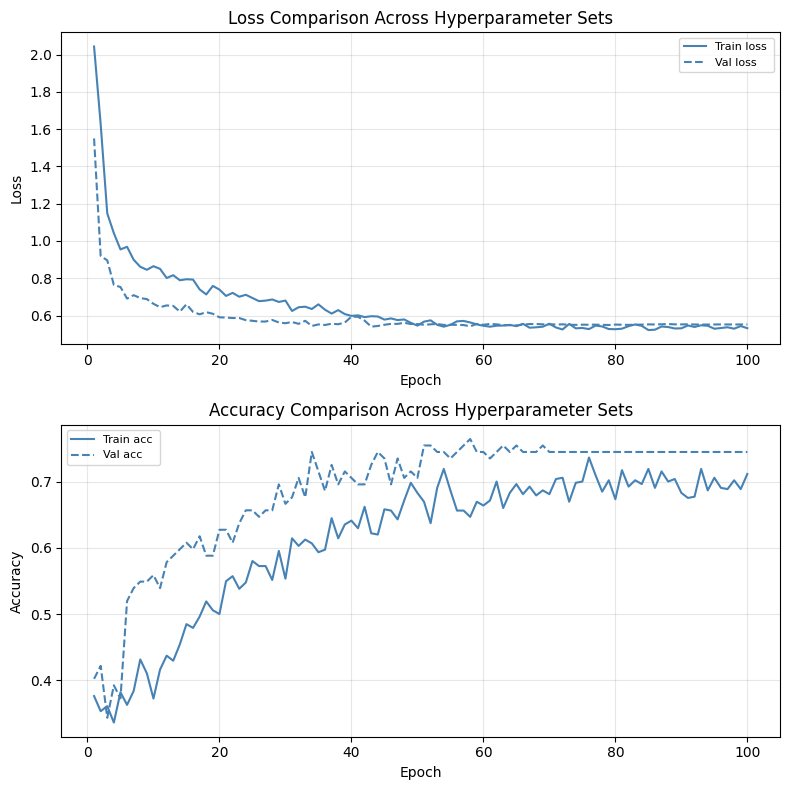

In [18]:
# Loss & Accuracy Visualization
print('[4/4] Training results visualization...')
plot_history(
    history,
    label='',
    save_path=os.path.join(RESULTS_DIR, 'training_history.png')
)

In [19]:
print('[INFO] Loading the best model from checkpoint...')
model = keras.models.load_model(MODEL_PATH)

[INFO] Loading the best model from checkpoint...


2026-07-08 13:30:16.375268: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



  Train Accuracy : 0.7462  (74.62%)
              precision    recall  f1-score   support

      KOA_EL       0.90      0.75      0.82       212
      KOA_MD       0.52      0.76      0.62       140
      KOA_SV       0.88      0.72      0.79       172

    accuracy                           0.75       524
   macro avg       0.77      0.75      0.74       524
weighted avg       0.79      0.75      0.76       524



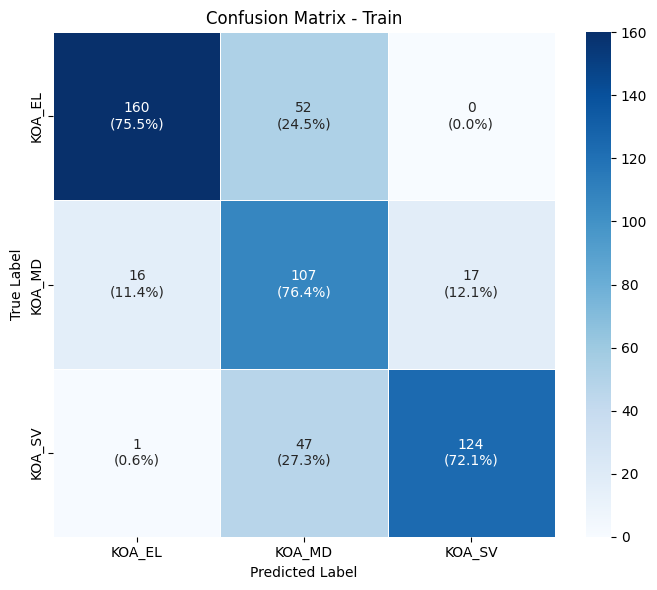

[OK] Confusion matrix saved: results/confusion_matrix_train.png


In [20]:
# Train set evaluation

train_acc = evaluate(model, X_train, y_train, dataset_name='Train')


  Val Accuracy : 0.7647  (76.47%)
              precision    recall  f1-score   support

      KOA_EL       0.77      0.67      0.71        15
      KOA_MD       0.66      0.76      0.70        33
      KOA_SV       0.84      0.80      0.82        54

    accuracy                           0.76       102
   macro avg       0.76      0.74      0.75       102
weighted avg       0.77      0.76      0.77       102



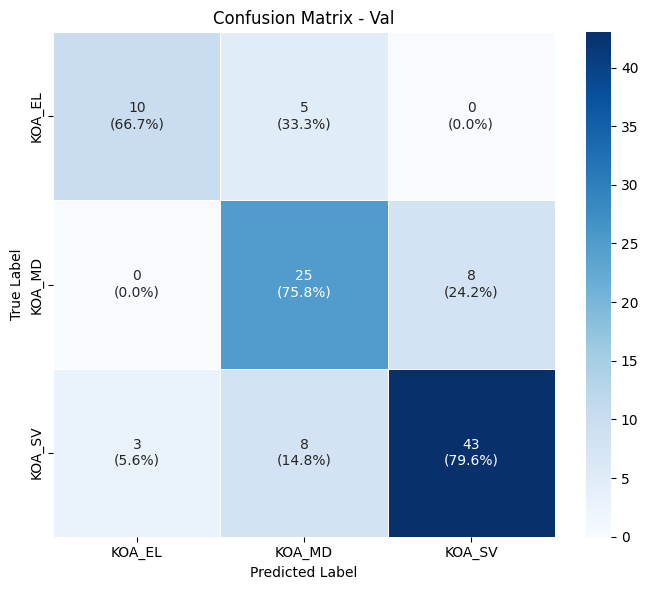

[OK] Confusion matrix saved: results/confusion_matrix_val.png


In [21]:
val_acc = evaluate(model, X_val, y_val, dataset_name='Val')


  Test Accuracy : 0.7364  (73.64%)
              precision    recall  f1-score   support

      KOA_EL       0.50      0.19      0.28        26
      KOA_MD       0.52      0.81      0.63        31
      KOA_SV       0.98      0.96      0.97        53

    accuracy                           0.74       110
   macro avg       0.67      0.65      0.63       110
weighted avg       0.74      0.74      0.71       110



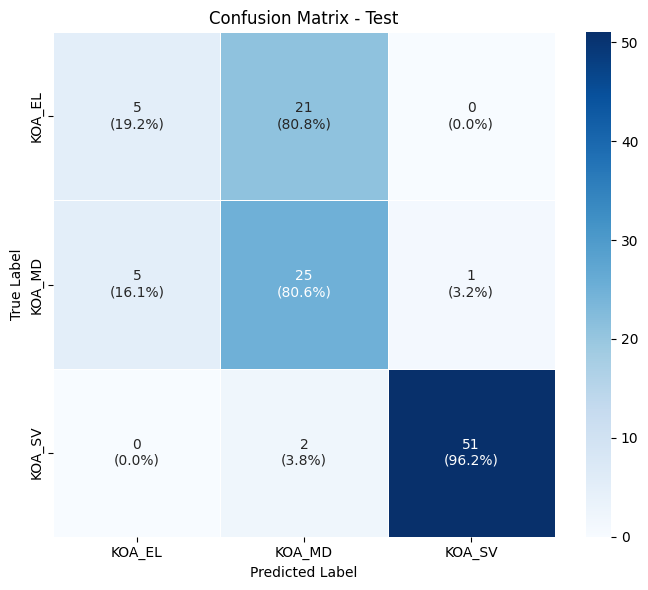

[OK] Confusion matrix saved: results/confusion_matrix_test.png


In [22]:
# Test set evaluation
test_acc = evaluate(model, X_test, y_test, dataset_name='Test')